## **데이터셋**

In [41]:
# url: https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/titanic.csv

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/titanic.csv")
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
786,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
787,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
788,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
789,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


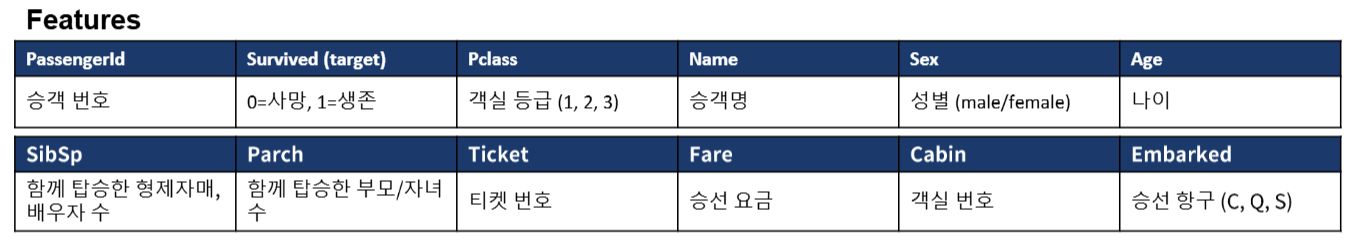

In [43]:
import os

# 운영체제에 맞춰 한글 폰트 지정 (Visual Studio 환경이면 'nt'인 Windows로 작동)
if os.name == 'nt':
    plt.rcParams['font.family'] = 'Malgun Gothic'
else:
    plt.rcParams['font.family'] = 'AppleGothic'

# 축의 음수(-) 기호가 깨지는 현상 방지x
plt.rcParams['axes.unicode_minus'] = False

In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 791 entries, 0 to 790
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  791 non-null    int64  
 1   Survived     791 non-null    int64  
 2   Pclass       791 non-null    int64  
 3   Name         791 non-null    str    
 4   Sex          791 non-null    str    
 5   Age          614 non-null    float64
 6   SibSp        791 non-null    int64  
 7   Parch        791 non-null    int64  
 8   Ticket       791 non-null    str    
 9   Fare         791 non-null    float64
 10  Cabin        182 non-null    str    
 11  Embarked     789 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 74.3 KB


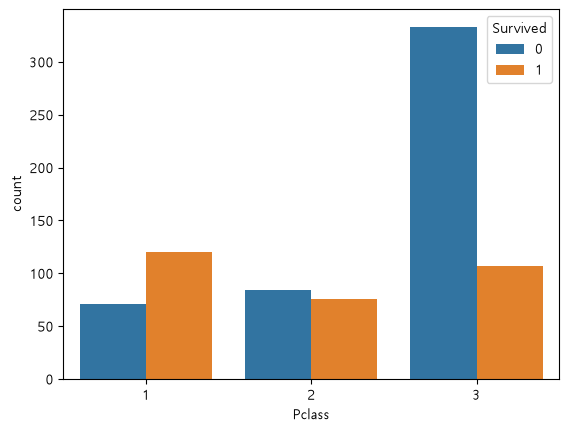

In [45]:
sns.countplot(df, x = "Pclass", hue = "Survived")
plt.show()

## **결측치 처리**

In [46]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          609
Embarked         2
dtype: int64

In [47]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
786,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
787,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
788,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
789,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [48]:
df["Embarked"].value_counts()

Embarked
S    567
C    149
Q     73
Name: count, dtype: int64

In [49]:
df["Embarked"] = df["Embarked"].fillna("S")  # 최다 빈도 S로 채우기

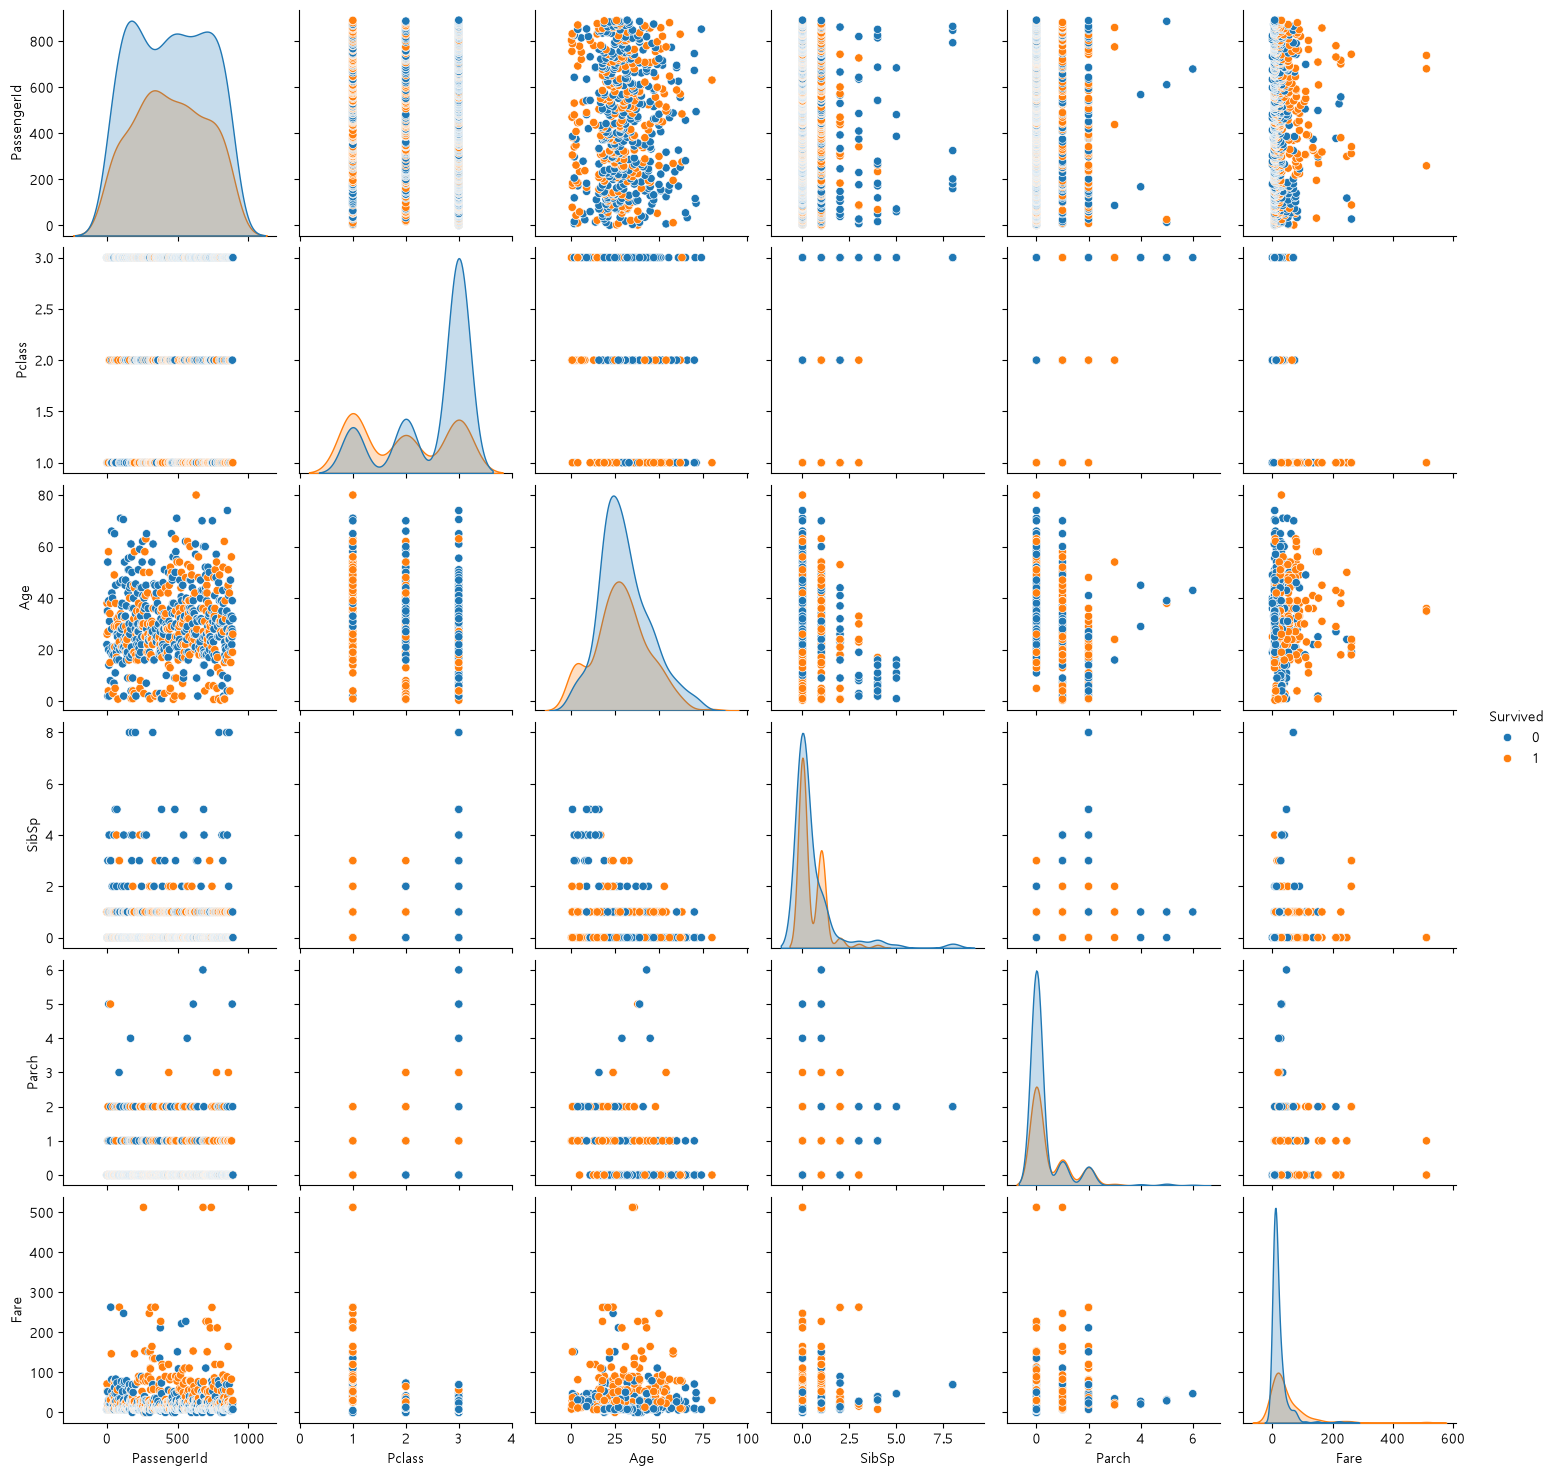

In [50]:
sns.pairplot(df, hue = "Survived")
plt.show()

In [51]:
df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)  #호칭에 따른 분류

<>:1: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:1: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
C:\Users\user\AppData\Local\Temp\ipykernel_13668\2338284837.py:1: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
  df['Title'] = df['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)  #호칭에 따른 분류


In [52]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1  # 가족 규모 생성


In [53]:
df['Fare_bin'] = pd.qcut(df['Fare'], 4, labels=['Low', 'Medium', 'High', 'Very High'])  # 요금 구간화하기

In [54]:
df['Age'] = df['Age'].fillna(df.groupby('Title')['Age'].transform('median'))  # 해당 호칭 그룹의 중앙값으로 대치

In [ ]:
# 3-2. 혼자 탑승 여부 (IsAlone) 생성
df['IsAlone'] = 0 # 모두 0으로 초기화
df.loc[df['FamilySize'] == 1, 'IsAlone'] = 1 # 가족 수가 1면 1로 변경

In [56]:
df = df.drop(["PassengerId", "Ticket", "Cabin", "Name", "Fare"],  axis = 1)

In [57]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Embarked,Title,FamilySize,Fare_bin,IsAlone
0,0,3,male,22.0,1,0,S,Mr,2,Low,0
1,1,1,female,38.0,1,0,C,Mrs,2,Very High,0
2,1,3,female,26.0,0,0,S,Miss,1,Medium,1
3,1,1,female,35.0,1,0,S,Mrs,2,Very High,0
4,0,3,male,35.0,0,0,S,Mr,1,Medium,1
...,...,...,...,...,...,...,...,...,...,...,...
786,0,2,male,27.0,0,0,S,Rev,1,Medium,1
787,1,1,female,19.0,0,0,S,Miss,1,High,1
788,0,3,female,22.0,1,2,S,Miss,4,High,0
789,1,1,male,26.0,0,0,C,Mr,1,High,1


## **범주형 데이터 원핫인코딩**

In [58]:
df = pd.get_dummies(df, columns=['Sex', 'Embarked', 'Title', 'Fare_bin'], drop_first=True)

In [59]:
df

,Survived,Pclass,Age,SibSp,Parch,FamilySize,IsAlone,Sex_male,Embarked_Q,Embarked_S,...,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir,Fare_bin_Medium,Fare_bin_High,Fare_bin_Very High
0,0,3,22.0,1,0,2,0,True,False,True,...,False,False,True,False,False,False,False,False,False,False
1,1,1,38.0,1,0,2,0,False,False,False,...,False,False,False,True,False,False,False,False,False,True
2,1,3,26.0,0,0,1,1,False,False,True,...,False,False,False,False,False,False,False,True,False,False
3,1,1,35.0,1,0,2,0,False,False,True,...,False,False,False,True,False,False,False,False,False,True
4,0,3,35.0,0,0,1,1,True,False,True,...,False,False,True,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
786,0,2,27.0,0,0,1,1,True,False,True,...,False,False,False,False,False,True,False,True,False,False
787,1,1,19.0,0,0,1,1,False,False,True,...,False,False,False,False,False,False,False,False,True,False
788,0,3,22.0,1,2,4,0,False,False,True,...,False,False,False,False,False,False,False,False,True,False
789,1,1,26.0,0,0,1,1,True,False,False,...,False,False,True,False,False,False,False,False,True,False


## **데이터 분할하기**

In [60]:
from sklearn.model_selection import train_test_split

X = df.drop("Survived", axis = 1)
y = df["Survived"]

In [61]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=101)

In [62]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((553, 27), (238, 27), (553,), (238,))

## **이상치 확인하기**

In [63]:
# def find_whiskers(data, column):
#     Q1 = data[column].quantile(0.25)
#     Q3 = data[column].quantile(0.75)
#     iqr = Q3 - Q1
#     lower = Q1 - iqr*1.5
#     upper = Q3 + iqr*1.5
#     return lower, upper 

In [64]:
# numeric_cols = X_train.select_dtypes(include="number").columns
# numeric_cols

In [65]:
# d = {} 
# for c in numeric_cols:
#     lower, upper = find_whiskers(df, c)
#     d[c] = (lower, upper)
#     outliers = ((df[c] < lower) | (df[c] > upper)).sum()
#     print(f"{c}: {outliers}")


In [66]:
# sns.boxplot(data=X_train, x = "Age")  # 갓난아기일 수 있음

In [67]:
# sns.boxplot(data=X_train, x = "Fare")

## **다중공선성 확인하기**

In [68]:
# sns.heatmap(X_train.corr(), annot=True, cmap="Blues")
# plt.show()

## **Feature Scaling**

In [69]:
# code here
# from sklearn.preprocessing import StandardScaler

# scaler = StandardScaler()

# X_train = scaler.fit_transform(X_train)
# X_test = scaler.transform(X_test)

In [70]:
# from sklearn.decomposition import PCA
# from sklearn.neighbors import KNeighborsClassifier
# from sklearn.cluster import KMeans

# pca = PCA(n_components=2)

In [71]:
# X_train_pca = pca.fit_transform(X_train)
# X_test_pca = pca.transform(X_test)

In [72]:
# plt.figure(figsize=(5,3))
# sns.scatterplot(x = X_train_pca[:,0], y = X_train_pca[:,1], hue = y_train)
# plt.show()

In [73]:
# # code here
# # 1 ~ n까지 홀수들만 시도

# def elbow_method(n):
#     errors = []
#     for k in range(1, n+1, 2):
#         model = KNeighborsClassifier(k)
#         model.fit(X_train_pca, y_train)
#         # 예측
#         y_pred = model.predict(X_test_pca)
#         errors.append((y_pred != y_test).mean())


#     # 테스트 다 끝난다음, 시각화
#     plt.figure(figsize=(20,10))
#     plt.title("elbow method")
#     sns.lineplot(x = range(1, n+1, 2), y = errors, marker = 'o')
#     plt.xticks(range(1, n+1, 1), fontsize = 15)
#     plt.show()

In [74]:
# elbow_method(15)

In [75]:
# model_knn = KNeighborsClassifier(5)

In [76]:
# model_knn.fit(X_train_pca, y_train)

In [77]:
# y_pred_knn = model_knn.predict(X_test_pca)

In [78]:
# evaluate_model(y_test, y_pred_knn)

In [79]:
# def elbow_method_kmeans():
#     inertia = []
#     # k centroid만큼 KNN처럼 때려보고 intertia값을 비교해서 제일 최적화된 값을 우리의 k로 설정
#     for k in range(1, 11):
#         kmeans = KMeans(n_clusters = k, init="k-means++")
#         kmeans.fit(X_train_pca)  # 학습
#         inertia.append(kmeans.inertia_)  # k개의 그루븡로 clustering했을 때의 wcss를 일단 리스트에 순서대로 저장

#     #시각화
#     plt.figure(figsize=(5,3))
#     sns.lineplot(x = range(1, 11), y = inertia, linestyle = "--", marker = "^")
#     plt.xticks(range(1,11))
#     plt.show()

In [80]:
# elbow_method_kmeans()

In [81]:
# model_kmean = KMeans(n_clusters=3)

In [82]:
# model_kmean.fit(X_train_pca, y_train)

In [83]:
# y_pred_kmean = model_kmean.predict(X_test_pca)

In [84]:
# evaluate_model(y_test, y_pred_kmean)

## **모델 학습**

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# (데이터 로드, 파생 변수 생성, 결측치 대체 등 이전 전처리 코드는 동일하게 유지)

# 1. 미세 성능을 끌어올리기 위한 세밀한 파라미터 그리드
param_grid = {
    'n_estimators': [200, 300, 500],
    'max_depth': [4, 5, 6, 7],
    'min_samples_split': [2, 4, 6],
    'min_samples_leaf': [1, 2, 3]
}

rf_model = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(
    estimator=rf_model, 
    param_grid=param_grid, 
    cv=5, 
    scoring='accuracy', 
    verbose=2,          
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print(f"\n최적 파라미터: {grid_search.best_params_}")

# 9. 최종 테스트 데이터 평가
best_rf_model = grid_search.best_estimator_
y_pred = best_rf_model.predict(X_test)
final_accuracy = accuracy_score(y_test, y_pred)
print(f"새로운 특성을 추가한 최종 예측 정확도: {final_accuracy * 100:.2f}%")

Fitting 5 folds for each of 108 candidates, totalling 540 fits

최적 파라미터: {'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 4, 'n_estimators': 200}
새로운 특성을 추가한 최종 예측 정확도: 84.03%


## **모델 평가**

In [86]:
# code here
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
def evaluate_model(y_true, y_pred):
    print(f"accuray: {accuracy_score(y_test, y_pred)}")
    print(classification_report(y_true, y_pred))
    plt.figure(figsize=(5,3))
    sns.heatmap(confusion_matrix(y_test, y_pred), cmap = "Blues", annot = True)
    plt.show()

## **모델 평가**

In [87]:
sub = pd.read_csv("titanic_submission.csv")
sub

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,660,1,"Newell, Mr. Arthur Webster",male,58.0,0,2,35273,113.2750,D48,C
1,353,3,"Elias, Mr. Tannous",male,15.0,1,1,2695,7.2292,NaN,C
2,667,2,"Butler, Mr. Reginald Fenton",male,25.0,0,0,234686,13.0000,NaN,S
3,545,1,"Douglas, Mr. Walter Donald",male,50.0,1,0,PC 17761,106.4250,C86,C
4,10,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C
...,...,...,...,...,...,...,...,...,...,...,...
95,430,3,"Pickard, Mr. Berk (Berk Trembisky)",male,32.0,0,0,SOTON/O.Q. 392078,8.0500,E10,S
96,500,3,"Svensson, Mr. Olof",male,24.0,0,0,350035,7.7958,NaN,S
97,822,3,"Lulic, Mr. Nikola",male,27.0,0,0,315098,8.6625,NaN,S
98,361,3,"Skoog, Mr. Wilhelm",male,40.0,1,4,347088,27.9000,NaN,S


In [88]:
sub['Title'] = sub['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)

<>:1: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:1: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
C:\Users\user\AppData\Local\Temp\ipykernel_13668\832897163.py:1: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
  sub['Title'] = sub['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)


In [89]:
sub['FamilySize'] = sub['SibSp'] + sub['Parch'] + 1

In [90]:
ids = sub["PassengerId"]

In [91]:
sub['Fare_bin'] = pd.qcut(sub['Fare'], 4, labels=['Low', 'Medium', 'High', 'Very High'])  # 요금 구간화하기

In [92]:
# 3-2. 혼자 탑승 여부 (IsAlone) 생성
sub['IsAlone'] = 0 # 모두 0으로 초기화
sub.loc[sub['FamilySize'] == 1, 'IsAlone'] = 1 # 가족 수가 1이면 1로 변경

In [93]:
sub = sub.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin', "Fare"])

In [94]:
sub = pd.get_dummies(sub, columns=['Sex', 'Embarked', 'Title', 'Fare_bin'], drop_first=True)

In [95]:
# 3. 중요: 훈련 데이터(X_train)와 제출 데이터(sub)의 컬럼을 똑같이 맞추기
# 훈련 시 존재했던 특성이 sub에 없으면 에러가 발생하므로 맞춰주는 작업입니다.
# X_train은 앞서 훈련에 사용한 데이터프레임입니다.
sub = sub.reindex(columns=X_train.columns, fill_value=0)

In [96]:
y_pred_sub = best_rf_model.predict(sub)

In [97]:
y_pred_sub = pd.DataFrame(y_pred_sub, columns=["Survived"])

In [98]:
pd.concat([ids, y_pred_sub], axis =1).to_csv("titanic.csv", index=False)